In [1]:
# ============================================================
# NOTEBOOK 10
# Confidence-Driven Adaptive Multi-Sensor Fusion
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 120

print("="*70)
print("NOTEBOOK 10")
print("Confidence-Driven Adaptive Multi-Sensor Fusion")
print("="*70)

NOTEBOOK 10
Confidence-Driven Adaptive Multi-Sensor Fusion


In [2]:
# ============================================================
# Cell 2
# Load Adaptive Sensor Weights
# ============================================================

PROJECT_ROOT = Path(
    r"D:\Research\Papers\Paper_2"
)

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

DRIVE = "2011_09_26_drive_0001_sync"

fusion = pd.read_csv(

    RESULT_DIR /

    f"adaptive_sensor_weights_{DRIVE}.csv"

)

print("=" * 70)

print("Adaptive Sensor Weight Dataset Loaded")

print("=" * 70)

print("Drive :", DRIVE)

print("Shape :", fusion.shape)

print("=" * 70)

display(fusion.head())

Adaptive Sensor Weight Dataset Loaded
Drive : 2011_09_26_drive_0001_sync
Shape : (108, 14)


,Frame,Camera Confidence,GPS Confidence,IMU Confidence,Camera Confidence Stability,GPS Confidence Stability,IMU Confidence Stability,Camera Confidence Reliability,GPS Confidence Reliability,IMU Confidence Reliability,Camera Weight,GPS Weight,IMU Weight,Weight Sum
0,0,0.195333,0.402966,0.716265,0.000000,0.000000,0.000000,0.195333,0.402966,0.716265,0.148592,0.306539,0.544869,1.0
1,1,0.132514,0.402966,0.716265,0.044420,0.000000,0.000000,0.105616,0.402966,0.716265,0.086228,0.328993,0.584779,1.0
2,2,0.074723,0.431558,0.603993,0.060323,0.016508,0.064820,0.054125,0.416246,0.493813,0.056135,0.431708,0.512156,1.0
3,3,0.119024,0.433646,0.597081,0.049834,0.017132,0.066875,0.091919,0.417678,0.484709,0.092445,0.420070,0.487484,1.0
4,4,0.257200,0.403218,0.843376,0.071262,0.016204,0.100982,0.173443,0.389175,0.603699,0.148710,0.333678,0.517612,1.0


In [3]:
# ============================================================
# Dataset Summary
# ============================================================

print("="*70)
print("Fusion Dataset Summary")
print("="*70)

print("Total Frames :", len(fusion))
print("Total Columns:", len(fusion.columns))

display(

fusion[[

"Camera Confidence",

"GPS Confidence",

"IMU Confidence",

"Camera Weight",

"GPS Weight",

"IMU Weight"

]].describe()

)

Fusion Dataset Summary
Total Frames : 108
Total Columns: 14


,Camera Confidence,GPS Confidence,IMU Confidence,Camera Weight,GPS Weight,IMU Weight
count,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000
mean,0.407729,0.581366,0.743690,0.216575,0.424380,0.359045
std,0.270209,0.303771,0.190172,0.158060,0.207270,0.151497
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.194217,0.345248,0.640359,0.113503,0.282824,0.266719
50%,0.356431,0.732142,0.753984,0.168581,0.468606,0.360754
75%,0.606354,0.810752,0.896143,0.285453,0.580124,0.435613
max,1.000000,1.000000,1.000000,0.774826,0.801296,0.860470


In [4]:
# ============================================================
# Confidence-Driven Adaptive Sensor Fusion
# ============================================================

fusion["Fused Confidence"] = (

      fusion["Camera Confidence"]

    * fusion["Camera Weight"]

    +

      fusion["GPS Confidence"]

    * fusion["GPS Weight"]

    +

      fusion["IMU Confidence"]

    * fusion["IMU Weight"]

)

display(

fusion[[

"Frame",

"Camera Confidence",

"GPS Confidence",

"IMU Confidence",

"Camera Weight",

"GPS Weight",

"IMU Weight",

"Fused Confidence"

]].head()

)

print("="*70)

print("Average Fused Confidence :",

round(

fusion["Fused Confidence"].mean(),

3

))

print("Maximum Fused Confidence :",

round(

fusion["Fused Confidence"].max(),

3

))

print("Minimum Fused Confidence :",

round(

fusion["Fused Confidence"].min(),

3

))

print("="*70)

,Frame,Camera Confidence,GPS Confidence,IMU Confidence,Camera Weight,GPS Weight,IMU Weight,Fused Confidence
0,0,0.195333,0.402966,0.716265,0.148592,0.306539,0.544869,0.542820
1,1,0.132514,0.402966,0.716265,0.086228,0.328993,0.584779,0.562856
2,2,0.074723,0.431558,0.603993,0.056135,0.431708,0.512156,0.499841
3,3,0.119024,0.433646,0.597081,0.092445,0.420070,0.487484,0.484233
4,4,0.257200,0.403218,0.843376,0.148710,0.333678,0.517612,0.609335


Average Fused Confidence : 0.697
Maximum Fused Confidence : 0.939
Minimum Fused Confidence : 0.304


In [5]:
# ============================================================
# Cell 5
# Temporal Confidence Smoothing (EMA)
# ============================================================

ALPHA = 0.30

fusion["Smoothed Confidence"] = (

    fusion["Fused Confidence"]

    .ewm(

        alpha=ALPHA,

        adjust=False

    )

    .mean()

)

display(

fusion[[

"Frame",

"Fused Confidence",

"Smoothed Confidence"

]].head()

)

print("="*70)

print("EMA Smoothing Completed")

print("Alpha :", ALPHA)

print("="*70)

,Frame,Fused Confidence,Smoothed Confidence
0,0,0.542820,0.542820
1,1,0.562856,0.548831
2,2,0.499841,0.534134
3,3,0.484233,0.519164
4,4,0.609335,0.546215


EMA Smoothing Completed
Alpha : 0.3


In [6]:
# ============================================================
# Cell 6
# Localization Reliability Score (LRS)
# ============================================================

WINDOW = 5

# ------------------------------------------------------------
# Temporal Confidence Variability
# ------------------------------------------------------------

fusion["Confidence Std"] = (

    fusion["Smoothed Confidence"]

    .rolling(

        window=WINDOW,

        min_periods=1

    )

    .std()

)

fusion["Confidence Std"] = (

    fusion["Confidence Std"]

    .fillna(0)

)

# ------------------------------------------------------------
# Normalize Temporal Variability
# ------------------------------------------------------------

std = fusion["Confidence Std"]

fusion["Normalized Std"] = (

    std - std.min()

) / (

    std.max() - std.min() + 1e-8

)

# ------------------------------------------------------------
# Stability Confidence
# ------------------------------------------------------------

GAMMA = 1.5

fusion["Stability Confidence"] = np.exp(

    -GAMMA *

    fusion["Normalized Std"]

)

# ------------------------------------------------------------
# Localization Reliability Score (LRS)
# ------------------------------------------------------------

ALPHA = 0.60      # Confidence Contribution

BETA = 0.40       # Stability Contribution

fusion["Localization Reliability Score"] = (

    ALPHA *

    fusion["Smoothed Confidence"]

    +

    BETA *

    fusion["Stability Confidence"]

)

# ------------------------------------------------------------
# Keep LRS within [0,1]
# ------------------------------------------------------------

fusion["Localization Reliability Score"] = (

    fusion["Localization Reliability Score"]

    .clip(0, 1)

)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(

fusion[[

    "Frame",

    "Smoothed Confidence",

    "Confidence Std",

    "Normalized Std",

    "Stability Confidence",

    "Localization Reliability Score"

]].head()

)

print("=" * 70)

print("Localization Reliability Score Generated Successfully")

print("=" * 70)

print(f"Average Smoothed Confidence   : {fusion['Smoothed Confidence'].mean():.3f}")

print(f"Average Stability Confidence  : {fusion['Stability Confidence'].mean():.3f}")

print(f"Average Localization Score    : {fusion['Localization Reliability Score'].mean():.3f}")

print("=" * 70)

,Frame,Smoothed Confidence,Confidence Std,Normalized Std,Stability Confidence,Localization Reliability Score
0,0,0.542820,0.000000,0.000000,1.000000,0.725692
1,1,0.548831,0.004250,0.041489,0.939664,0.705164
2,2,0.534134,0.007389,0.072128,0.897456,0.679463
3,3,0.519164,0.012882,0.125751,0.828095,0.642736
4,4,0.546215,0.012016,0.117291,0.838671,0.663197


Localization Reliability Score Generated Successfully
Average Smoothed Confidence   : 0.697
Average Stability Confidence  : 0.705
Average Localization Score    : 0.700


In [7]:
# ============================================================
# Cell 7
# Adaptive Localization Classification
# ============================================================

excellent = fusion["Localization Reliability Score"].quantile(0.90)

high = fusion["Localization Reliability Score"].quantile(0.70)

moderate = fusion["Localization Reliability Score"].quantile(0.40)

low = fusion["Localization Reliability Score"].quantile(0.10)


def classify(score):

    if score >= excellent:

        return "Excellent"

    elif score >= high:

        return "High"

    elif score >= moderate:

        return "Moderate"

    elif score >= low:

        return "Low"

    else:

        return "Poor"


fusion["Localization Level"] = (

    fusion["Localization Reliability Score"]

    .apply(classify)

)

display(

fusion[[

"Localization Reliability Score",

"Localization Level"

]].head()

)

counts = fusion["Localization Level"].value_counts()

display(counts)

print("="*70)

print("Adaptive Percentile Thresholds")

print("="*70)

print(f"Excellent : {excellent:.3f}")

print(f"High       : {high:.3f}")

print(f"Moderate   : {moderate:.3f}")

print(f"Low        : {low:.3f}")

print("="*70)

,Localization Reliability Score,Localization Level
0,0.725692,Moderate
1,0.705164,Moderate
2,0.679463,Low
3,0.642736,Low
4,0.663197,Low


Localization Level
Moderate     32
Low          32
High         22
Poor         11
Excellent    11
Name: count, dtype: int64

Adaptive Percentile Thresholds
Excellent : 0.811
High       : 0.764
Moderate   : 0.704
Low        : 0.527


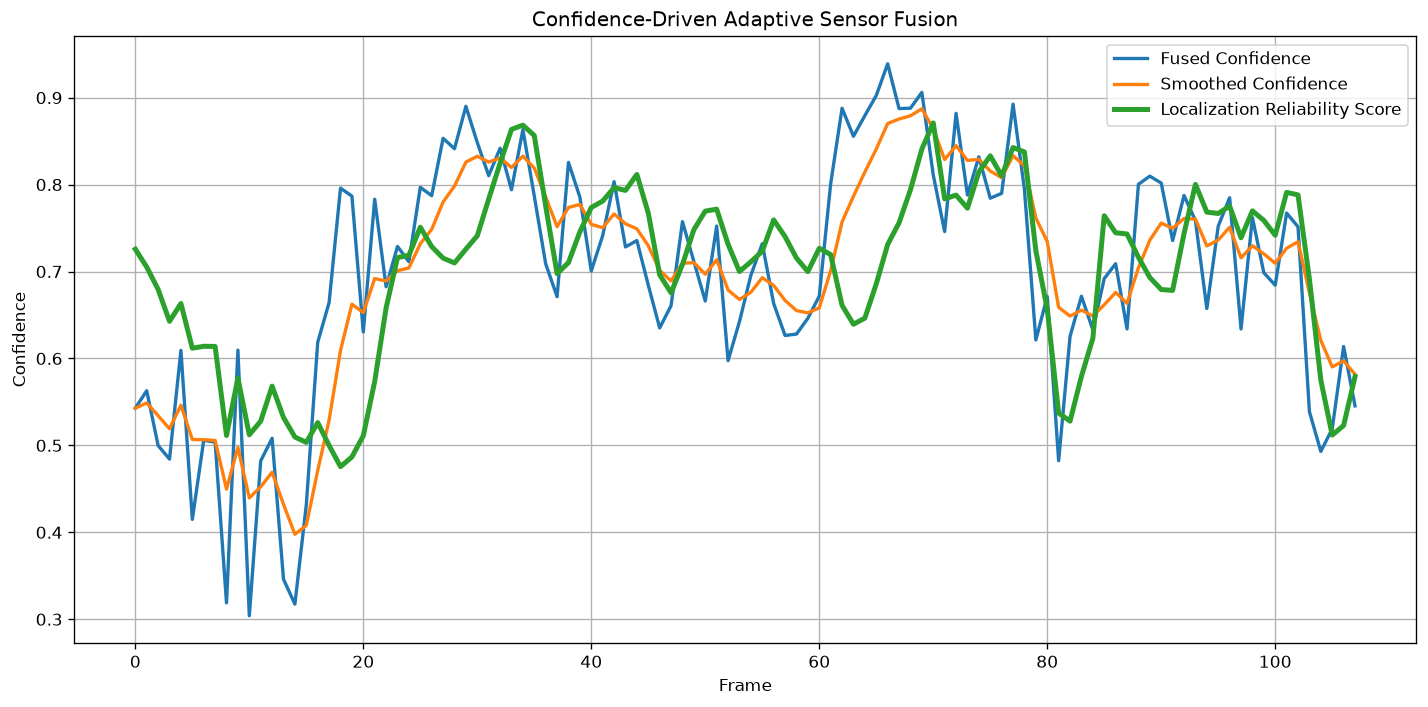

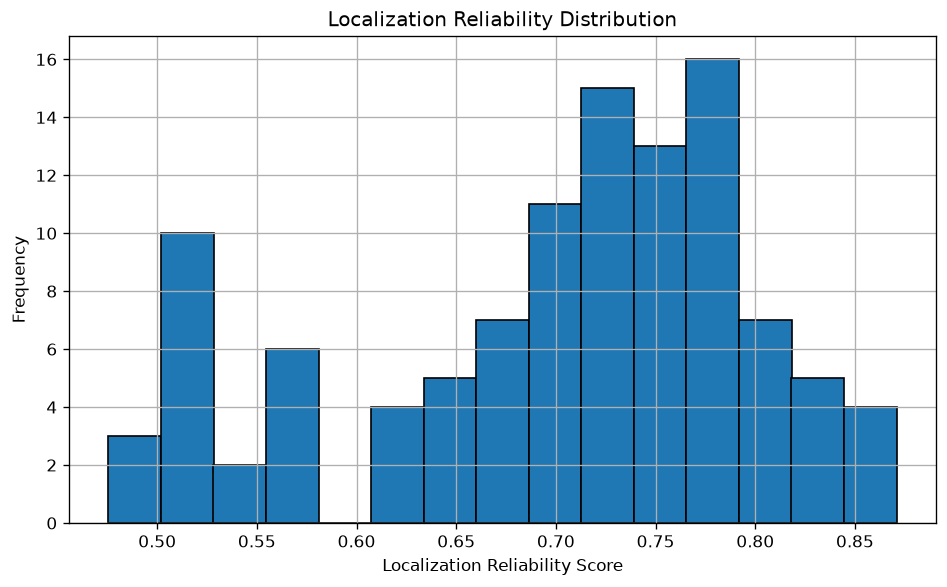

Localization Level
Moderate     32
Low          32
High         22
Poor         11
Excellent    11
Name: count, dtype: int64

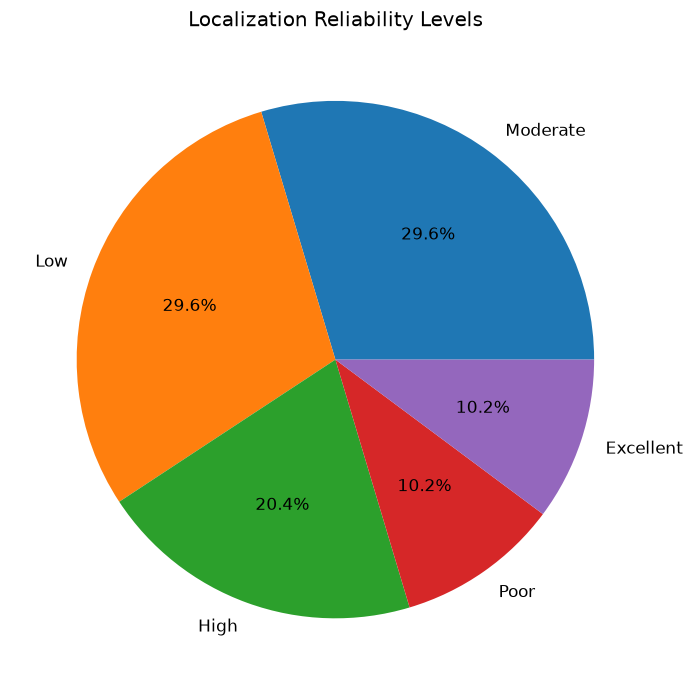

In [8]:
# ============================================================
# Cell 8
# Localization Reliability Analysis
# ============================================================

plt.figure(figsize=(12,6))

plt.plot(
    fusion["Frame"],
    fusion["Fused Confidence"],
    linewidth=2,
    label="Fused Confidence"
)

plt.plot(
    fusion["Frame"],
    fusion["Smoothed Confidence"],
    linewidth=2,
    label="Smoothed Confidence"
)

plt.plot(
    fusion["Frame"],
    fusion["Localization Reliability Score"],
    linewidth=3,
    label="Localization Reliability Score"
)

plt.grid(True)

plt.legend()

plt.xlabel("Frame")

plt.ylabel("Confidence")

plt.title("Confidence-Driven Adaptive Sensor Fusion")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "confidence_driven_sensor_fusion.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# Localization Reliability Distribution
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.hist(
    fusion["Localization Reliability Score"],
    bins=15,
    edgecolor="black"
)

plt.grid(True)

plt.xlabel("Localization Reliability Score")

plt.ylabel("Frequency")

plt.title("Localization Reliability Distribution")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "localization_reliability_distribution.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# Reliability Level Distribution
# ------------------------------------------------------------

counts = fusion["Localization Level"].value_counts()

display(counts)

plt.figure(figsize=(7,7))

plt.pie(

    counts,

    labels=counts.index,

    autopct="%1.1f%%"

)

plt.title("Localization Reliability Levels")

plt.savefig(

    FIGURE_DIR /

    "localization_reliability_levels.png",

    dpi=300

)

plt.show()

In [9]:
# ============================================================
# Cell 9
# Localization Statistics
# ============================================================

statistics = fusion[[

    "Camera Confidence",

    "GPS Confidence",

    "IMU Confidence",

    "Fused Confidence",

    "Smoothed Confidence",

    "Localization Reliability Score"

]].describe()

display(statistics)

summary = pd.DataFrame({

    "Metric":[

        "Average Camera Confidence",

        "Average GPS Confidence",

        "Average IMU Confidence",

        "Average Fused Confidence",

        "Average Smoothed Confidence",

        "Average Localization Reliability Score",

        "Maximum Localization Reliability Score",

        "Minimum Localization Reliability Score"

    ],

    "Value":[

        fusion["Camera Confidence"].mean(),

        fusion["GPS Confidence"].mean(),

        fusion["IMU Confidence"].mean(),

        fusion["Fused Confidence"].mean(),

        fusion["Smoothed Confidence"].mean(),

        fusion["Localization Reliability Score"].mean(),

        fusion["Localization Reliability Score"].max(),

        fusion["Localization Reliability Score"].min()

    ]

})

display(summary)

statistics.to_csv(

    RESULT_DIR /

    "localization_statistics.csv"

)

summary.to_csv(

    RESULT_DIR /

    "localization_summary.csv",

    index=False

)

,Camera Confidence,GPS Confidence,IMU Confidence,Fused Confidence,Smoothed Confidence,Localization Reliability Score
count,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000
mean,0.407729,0.581366,0.743690,0.697491,0.696650,0.699795
std,0.270209,0.303771,0.190172,0.139037,0.116782,0.100492
min,0.000000,0.000000,0.000000,0.304064,0.397758,0.475533
25%,0.194217,0.345248,0.640359,0.627632,0.654549,0.645483
50%,0.356431,0.732142,0.753984,0.711395,0.711867,0.721406
75%,0.606354,0.810752,0.896143,0.794759,0.774567,0.770237
max,1.000000,1.000000,1.000000,0.938943,0.887224,0.870884


,Metric,Value
0,Average Camera Confidence,0.407729
1,Average GPS Confidence,0.581366
2,Average IMU Confidence,0.743690
3,Average Fused Confidence,0.697491
4,Average Smoothed Confidence,0.696650
5,Average Localization Reliability Score,0.699795
6,Maximum Localization Reliability Score,0.870884
7,Minimum Localization Reliability Score,0.475533


,Camera Confidence,GPS Confidence,IMU Confidence,Fused Confidence,Localization Reliability Score
Camera Confidence,1.000000,-0.509826,0.054527,0.215869,0.382514
GPS Confidence,-0.509826,1.000000,0.088401,0.435000,0.175302
IMU Confidence,0.054527,0.088401,1.000000,0.518396,0.175256
Fused Confidence,0.215869,0.435000,0.518396,1.000000,0.617148
Localization Reliability Score,0.382514,0.175302,0.175256,0.617148,1.000000


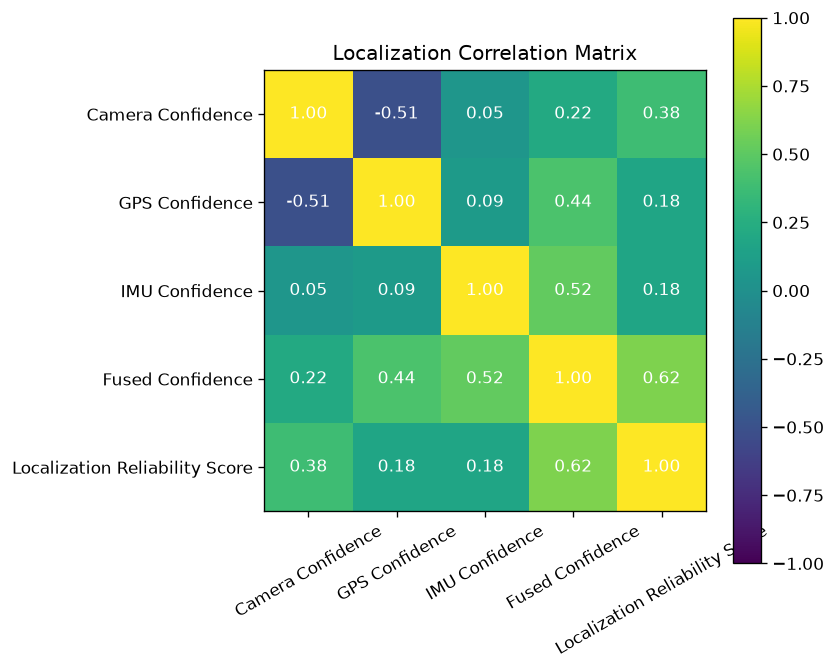

In [10]:
# ============================================================
# Cell 10
# Correlation Matrix
# ============================================================

correlation = fusion[[

"Camera Confidence",

"GPS Confidence",

"IMU Confidence",

"Fused Confidence",

"Localization Reliability Score"

]].corr()

display(correlation)

fig, ax = plt.subplots(figsize=(7,6))

image = ax.imshow(

    correlation,

    cmap="viridis",

    vmin=-1,

    vmax=1

)

for i in range(len(correlation.columns)):

    for j in range(len(correlation.columns)):

        ax.text(

            j,

            i,

            f"{correlation.iloc[i,j]:.2f}",

            ha="center",

            va="center",

            color="white",

            fontsize=10

        )

ax.set_xticks(range(len(correlation.columns)))

ax.set_xticklabels(

    correlation.columns,

    rotation=30

)

ax.set_yticks(range(len(correlation.columns)))

ax.set_yticklabels(

    correlation.columns

)

plt.colorbar(image)

plt.title("Localization Correlation Matrix")

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "localization_correlation_matrix.png",

    dpi=300

)

plt.show()

In [11]:
# ============================================================
# Cell 11
# Save Results
# ============================================================

fusion.to_csv(

    RESULT_DIR /

    f"confidence_driven_sensor_fusion_{DRIVE}.csv",

    index=False

)

statistics.to_csv(

    RESULT_DIR /

    f"fusion_statistics_{DRIVE}.csv"

)

summary.to_csv(

    RESULT_DIR /

    f"fusion_summary_{DRIVE}.csv",

    index=False

)

correlation.to_csv(

    RESULT_DIR /

    f"fusion_correlation_{DRIVE}.csv"

)

print("=" * 70)

print("Fusion Results Saved Successfully")

print("=" * 70)

print(f"confidence_driven_sensor_fusion_{DRIVE}.csv")

print(f"fusion_statistics_{DRIVE}.csv")

print(f"fusion_summary_{DRIVE}.csv")

print(f"fusion_correlation_{DRIVE}.csv")

print("=" * 70)

Fusion Results Saved Successfully
confidence_driven_sensor_fusion_2011_09_26_drive_0001_sync.csv
fusion_statistics_2011_09_26_drive_0001_sync.csv
fusion_summary_2011_09_26_drive_0001_sync.csv
fusion_correlation_2011_09_26_drive_0001_sync.csv


In [12]:
# ============================================================
# Cell 12
# Final Summary
# ============================================================

print("=" * 80)

print("NOTEBOOK 10 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print()

print(f"Average Camera Confidence      : {fusion['Camera Confidence'].mean():.3f}")

print(f"Average GPS Confidence         : {fusion['GPS Confidence'].mean():.3f}")

print(f"Average IMU Confidence         : {fusion['IMU Confidence'].mean():.3f}")

print()

print(f"Average Fused Confidence       : {fusion['Fused Confidence'].mean():.3f}")

print(f"Average Localization Score     : {fusion['Localization Reliability Score'].mean():.3f}")

print()

print("Generated Files")

print("----------------------------")

print(f"confidence_driven_sensor_fusion_{DRIVE}.csv")

print(f"fusion_statistics_{DRIVE}.csv")

print(f"fusion_summary_{DRIVE}.csv")

print(f"fusion_correlation_{DRIVE}.csv")

print()

print("READY FOR NOTEBOOK 11")

print("=" * 80)

NOTEBOOK 10 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync

Average Camera Confidence      : 0.408
Average GPS Confidence         : 0.581
Average IMU Confidence         : 0.744

Average Fused Confidence       : 0.697
Average Localization Score     : 0.700

Generated Files
----------------------------
confidence_driven_sensor_fusion_2011_09_26_drive_0001_sync.csv
fusion_statistics_2011_09_26_drive_0001_sync.csv
fusion_summary_2011_09_26_drive_0001_sync.csv
fusion_correlation_2011_09_26_drive_0001_sync.csv

READY FOR NOTEBOOK 11


In [13]:
# ============================================================
# Cell 13
# Pipeline Status
# ============================================================

print("=" * 80)

print("PIPELINE STATUS")

print("=" * 80)

print("""

Notebook 03 ✓ Dataset Loading & Preprocessing

Notebook 04 ✓ Camera Quality Metrics

Notebook 05 ✓ Camera Confidence Estimation

Notebook 06 ✓ Camera Adaptive Dynamic Weight

Notebook 07 ✓ GPS & IMU Quality Metrics

Notebook 08 ✓ GPS & IMU Confidence Estimation

Notebook 09 ✓ Adaptive Multi-Sensor Weight Generation

Notebook 10 ✓ Confidence-Driven Adaptive Sensor Fusion

Notebook 11 → Confidence-Driven Adaptive EKF

Notebook 12 → Learning-Based Localization Reliability Prediction

""")

print("=" * 80)

PIPELINE STATUS


Notebook 03 ✓ Dataset Loading & Preprocessing

Notebook 04 ✓ Camera Quality Metrics

Notebook 05 ✓ Camera Confidence Estimation

Notebook 06 ✓ Camera Adaptive Dynamic Weight

Notebook 07 ✓ GPS & IMU Quality Metrics

Notebook 08 ✓ GPS & IMU Confidence Estimation

Notebook 09 ✓ Adaptive Multi-Sensor Weight Generation

Notebook 10 ✓ Confidence-Driven Adaptive Sensor Fusion

Notebook 11 → Confidence-Driven Adaptive EKF

Notebook 12 → Learning-Based Localization Reliability Prediction




In [14]:
best = fusion.loc[
    fusion["Localization Reliability Score"].idxmax()
]

worst = fusion.loc[
    fusion["Localization Reliability Score"].idxmin()
]

print()

print("Best Localization Frame")

print("----------------------------")

print(best[[
    "Frame",
    "Localization Reliability Score"
]])

print()

print("Worst Localization Frame")

print("----------------------------")

print(worst[[
    "Frame",
    "Localization Reliability Score"
]])


Best Localization Frame
----------------------------
Frame                                   70
Localization Reliability Score    0.870884
Name: 70, dtype: object

Worst Localization Frame
----------------------------
Frame                                   18
Localization Reliability Score    0.475533
Name: 18, dtype: object
